# Metadatos, versionado y repetición longitudinal en FAERS

1. ¿Cuál es la diferencia entre un safe tyreportid y una safetyreportversion?  
El safereportid es el indentificador único asignado al caso o reporte en el sistema de FAERS el cual mantiene constante para un mismo evento.
El safetyreportversion indica el numero de version de dicho caso

2. ¿Por qué un mismo safetyreportid puede aparecer en más de un QDE?  
   Porque FAERS utiliza una estructura de casos y versiones donde un mismo caso puede reaparecer en trimestres QDE posteriores debido a actualizaciones, correcciones o liberaciones continuas de información por parte de las autoridades.

3. Explica la diferencia entre:  

* una *aparición* de un caso: corresponde a cada vez que un safetyreportid se encuentra dentro de un archivo QDE trimestral.  
* un *caso único*: se refiere a la entidad unica representada por safetyreportid sin importar cuantas veces reaparezca.    
* una *versión*: numero especifico de safetyreportversion que describe el estado del reporte.  
* una *transición longitudinal*: la comparacion secuencial entre dos apariciones consecutivas del mismo caso a los largo del tiempo.


4. ¿Por qué encontrar el mismo safetyreportid en dos trimestres diferentes no significa automáticamente que exista un duplicado?  
   Porque la reaparición puede tratarse de un almacenamiento prolongado sin cambios (carryover) o de una version posterior que trae información actualizada por lo que no constituye un registro repetido. 

5. Explica que significa: 
    $$\Delta v = v_t -v_{t-}$$ : Representa la diferencia numerica de version entre dos apariciones consecutivas en el tiempo.
   ¿Cómo interpretarías los casos :?
   * $$\Delta v= 0$$  Ambas apariciones conservan exactamente la misma version.
   * $$\Delta v= 1$$ Representan una actualizacion consecutiva estandar donde la version aumneta en una unidad 
   * $$\Delta v\geq 1$$  Indica que hubo una o mas saltos de version que no aparecen registrados en los trimestres estudiados
     

6. ¿Qué es un fingerprint o huella digital en el contexto de este análisis? Explica para qué se utilizó y por qué resulta más conveniente que comparar manualmente todos los medicamentos y reacciones.  
   En un codigo hash generado a partir de los conjuntos normalizados de medicamentos y reacciones de un reporte. Es mucho mas conveniente porque permite comprobar de forma automatizada y rapida si dos registros contienen la misma informacion farmacologica sin requerir revisiones manuales texto por texto.

7. En el notebook se encontraron 131 transiciones con la misma versión. De ellas, 129 presentaron contenido exactamente igual y 2 mostraron cambios únicamente en términos de reacción coincidentes con un cambio de versión MedDRA. Explica qué nos enseña este resultado sobre la comparación longitudinal de los reportes FAERS.  
   Nos enseña que la mayoria de las apariciones con identica version corresponden a un *carryover* administrativo identico, pueden existir pequeñas modificaciones en las reacciones provocadas por cambios en los dicionarios externos como en el de MeDRA y no por alteraciones clinica reales en el paciente

8. ¿Por qué un cambio en reactionmeddrapt no necesariamente implica que haya cambiado clínicamente el reporte?  
   Porque puede deberse a una actualizacion en la version del diccionario de MeDRA  utilizado para codificar el termino preferido (PT) de un trimestre a otro, manteniendo intacto el trasfondo clinico del caso. 

9. Explica la diferencia entre: release_view y case_latest_view.
¿Qué pregunta responde cada una?
* *Release_view* :guarda una representacion de cada caso en cada trimestre en el que aparece. Responde preguntas sobre la dinamica de las publicaciones trimestrales, la persistencia y el efecto *carryover*
* *Case_latest_view* : mantiene unicamente la version mas reciente disponible para cada *safereportid* en una cohorte de casos únicos. Responde a análisis descriptivos globales, perfiles de seguridad, geografía y seriedad sin deduplicaciones.

10. ¿Por qué qde_period en case_latest_view no debe interpretarse como el trimestre en el que se originó el caso?  
    Porque en esta vista a cada caso se le asigna el QDE correspondiente al trimestre de su versión más receinte, por lo que no reprsenta su fecha de origen. 
    

11. ¿Por qué se decidió utilizar occurcountry como variable geográfica principal y no completar automáticamente sus valores faltantes con primarysourcecountry?  
    Porque representan conceptos distintos definidos por FAERS; *occurcountry* es el sitio donde sucedio el evento y *primarysourcecountry* es el país de la fuente primaria. Asumir que son iguales mediante una imputación directa podría introducir sesgos metodológicos 

2. Explica por qué no sería metodológicamente correcto aplicar una sola regla de deduplicación para todos los análisis de este proyecto.  
Porque los objetivos analíticos varían, mientras que el estudio temporal y de señales en liberaciones requiere la perspectiva longitudinal de *release_view*, las evaluaciones globales de casos o perfiles poblacionales exigen una cohorte unica, haciendo que una regla rígida única invalide información valiosa

# Parte B. Comprobación de resultados

## Ejercicio 1. Tamaño de las dos vistas

Carga: release_view_metadata.parquet y case_latest_view_metadata.parquet.  

Obtén:

* número de filas;
* número de safetyreportid distintos;
* porcentaje de reportes con serious_any = True;
* porcentaje de valores faltantes de occurcountry.  
Construye una tabla comparativa y explica brevemente por qué los resultados de las dos vistas no son idénticos.

In [1]:
import pandas as pd
from pathlib import Path

In [7]:
# 1. Cargar las vistas generadas (Secciones 13.3 y 13.6)
ruta_release_view = DERIVED_DIR / "release_view_metadata.parquet"
ruta_case_latest = DERIVED_DIR / "case_latest_view_metadata.parquet"

release_view = pd.read_parquet(ruta_release_view)
case_latest_view = pd.read_parquet(ruta_case_latest)


# 2. Función y tabla para la seriedad (Sección 13.11)
def resumen_seriedad(df, nombre):
  n = len(df)
  n_serious = df["serious_any"].sum()
  return {
      "view": nombre,
      "n_rows": n,
      "n_serious": int(n_serious),
      "pct_serious": 100 * n_serious / n,
  }


tabla_views_serious = pd.DataFrame(
    [
        resumen_seriedad(release_view, "release_view"),
        resumen_seriedad(case_latest_view, "case_latest_view"),
    ]
)
print("\nSERIEDAD SEGÚN VISTA")
display(tabla_views_serious)


# 3. Función y tabla para faltantes geográficos (Sección 13.12)
def resumen_geografia(df, nombre):
  n = len(df)
  n_missing = df["occurcountry"].isna().sum()
  return {
      "view": nombre,
      "n_rows": n,
      "occurcountry_missing": n_missing,
      "pct_occurcountry_missing": 100 * n_missing / n,
  }


tabla_views_geo = pd.DataFrame(
    [
        resumen_geografia(release_view, "release_view"),
        resumen_geografia(case_latest_view, "case_latest_view"),
    ]
)
print("\nFALTANTES GEOGRÁFICOS SEGÚN VISTA")
display(tabla_views_geo)

# 4. Verificación de safetyreportid distintos
print("IDs distintos en release_view:", release_view["safetyreportid"].nunique())
print(
    "IDs distintos en case_latest_view:",
    case_latest_view["safetyreportid"].nunique(),
)


SERIEDAD SEGÚN VISTA


,view,n_rows,n_serious,pct_serious
0,release_view,2437126,1368536,56.153683
1,case_latest_view,2189238,1208989,55.224192



FALTANTES GEOGRÁFICOS SEGÚN VISTA


,view,n_rows,occurcountry_missing,pct_occurcountry_missing
0,release_view,2437126,160926,6.603105
1,case_latest_view,2189238,155595,7.107267


IDs distintos en release_view: 2189238
IDs distintos en case_latest_view: 2189238


Realse contiene un aobservacion por cada combinacion trimestral en la que aparece un caso safetyreportid + qde_period, registrando un total de 2,437,126 filas, en contraste case_latest colapsa la infromación para conservar unicamente la version más reciente disponible en cada caso resultando en 2,189,238 filas 

## Ejercicio 2. Casos repetidos

Carga: case_history.parquet. Calcula:

* número total de casos;
* número y porcentaje de casos con una sola aparición;
* número y porcentaje de casos repetidos;
* número máximo de apariciones observado;
* número máximo de QDE en los que aparece un mismo caso.
* Comprueba si puedes recuperar aproximadamente el resultado: **213,737** casos repetidos.

Explica qué representa esta cantidad.

In [10]:
# Cargar la tabla con la historia de los casos 
case_history = pd.read_parquet(DERIVED_DIR / "case_history.parquet")

# numero total de casos 
n_total = len(case_history)

# numero y porcentaje de casos con una sola aparición 
n_single = (case_history["n_appearances"] == 1).sum()
pct_single = 100 * n_single / n_total

# numero y porcentaje de casos repetidos 
repeated_cases = case_history[case_history["n_appearances"] > 1].copy()
n_repeated = len(repeated_cases)
pct_repeated = 100 * n_repeated / n_total

# numero máximo de apariciones observadas 
max_appearances = case_history["n_appearances"].max()

# numero máximo de QDE en los que aparece un mismo caso 
max_qde = case_history["n_qde_periods"].max()

# Imprimir resultados
print(f"Numero total de casos: {n_total:,}")
print(f"Casos con una sola aparición: {n_single:,} ({pct_single:.2f}%)")
print(f"Casos repetidos: {n_repeated:,} ({pct_repeated:.2f}%)")
print(f"Maximo de apariciones observadas: {max_appearances}")
print(f"Maximo de QDE en los que aparece un mismo caso: {max_qde}")

Número total de casos: 2,189,238
Casos con una sola aparición: 1,975,501 (90.24%)
Casos repetidos: 213,737 (9.76%)
Máximo de apariciones observadas: 6
Máximo de QDE en los que aparece un mismo caso: 6


Son 213,737 representando el 9.76%, es la cantidad de casos que reaparecen en más de un trimestre, mostrando que un sector importante de la base experimenta procesos de seguimiento o actualizaciones a lo largo del tiempo.

## Ejercicio 3. Transiciones longitudinales

Carga: repeated_case_transitions_enriched.parquet.

Obtén el número total de transiciones y verifica que sea: **247,889**


Después calcula la frecuencia y el porcentaje de cada categoría de transition_class_check.

Identifica cuál es la categoría más frecuente y explica qué significa en términos de las actualizaciones de FAERS.

In [11]:
# Cargar la tabla enriquecida de transiciones 
ruta_transitions_enriched = (DERIVED_DIR / "repeated_case_transitions_enriched.parquet")
df_transitions_enriched = pd.read_parquet(ruta_transitions_enriched)

# Verificar el número total de transiciones
print(f"Total de transiciones: {len(df_transitions_enriched):,}")

# Calcular la frecuencia y el porcentaje de cada categoría de transición 
tabla_transition_class = (
    df_transitions_enriched["transition_class_check"]
    .value_counts()
    .rename_axis("transition_class")
    .reset_index(name="n_transitions")
)

tabla_transition_class["percentage"] = (
    100
    * tabla_transition_class["n_transitions"]
    / len(df_transitions_enriched)
)

# Mostrar la tabla resultante
display(tabla_transition_class)

Total de transiciones: 247,889


,transition_class,n_transitions,percentage
0,updated_version_same_content,114292,46.106120
1,updated_version_reaction_change,84780,34.200791
2,updated_version_drug_and_reaction_change,30319,12.230878
3,updated_version_drug_change,18367,7.409365
4,same_version_exact_content,129,0.052039
5,same_version_reaction_change_meddra_shift,2,0.000807


Tenemos que la categoría dominante es updated_version_same_content	 que representa el 46.10%   
Esto nos indica que cuando un reporte se actualiza a una versión posterior $$\Delta v= 0$$ es casi la mitad de los casos, los cambios corresponden a modificaciones administrativas de metadatos 

## Parte C. Visualización de resultados

Todas las gráficas deberán incluir:
título;
nombres de los ejes;
unidades o porcentajes cuando corresponda;
una breve interpretación debajo de la figura.  
No es suficiente mostrar la gráfica: se debe explicar en 2 a 4 líneas qué se observa y por qué puede ser importante para el análisis de farmacovigilancia.

### Gráfica 1. Número de reportes por QDE

Utiliza: release_view_metadata.parquet.

Construye una gráfica de barras con: $$x=qde\_period$$ y $$\text{y}=\text{numero de reportes} $$  
Responde:

¿El número de reportes permanece aproximadamente constante entre los seis QDE o se observan diferencias importantes?

In [14]:
pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ------------------- ------------------ 41.0/80.3 kB 326.8 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 496.6 kB/s eta 0:00:00
     ---------------------------------------- 0.0/132.6 kB ? eta -:--:--
     ----------------------------------- -- 122.9/132.6 kB 2.4 MB/s eta 0:00:01
     -------------------------------------- 132.6/132.6 kB 1.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
    --------------------------------------- 0.2/9.3 MB 5.3 MB/s eta 0:00:02
   - -------------------------------------- 0.3/9.3 MB 3.6 MB/s eta 0:00:03
   -- ------------------------------------- 0.6/9.3 MB 4.6 MB/s eta 0:00:02
   -- ------------------------------------- 0.6/9.3 MB 3.9 MB/s eta 0:00:03
   --- ------------------------------------ 0.7/9.3 MB 3.2 MB/s eta 0:00:03
   --- ------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


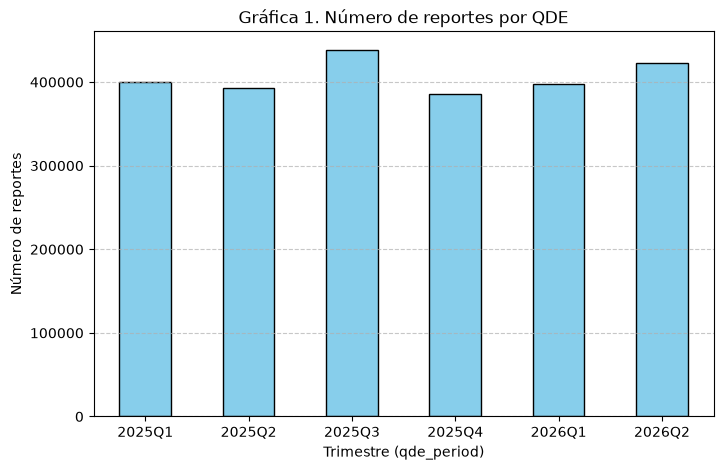

In [15]:
import matplotlib.pyplot as plt
release_view = pd.read_parquet(
    "derived/metadata/release_view_metadata.parquet")
conteo = release_view["qde_period"].value_counts().sort_index()

conteo.plot(kind="bar", color="skyblue", edgecolor="black", figsize=(8, 5))
plt.title("Gráfica 1. Número de reportes por QDE")
plt.xlabel("Trimestre (qde_period)")
plt.ylabel("Número de reportes")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Notamos que no pertenece totalmente constante, se observan diferencias importantes y fluctuaciones en el volumen de reportes notificados a lo largo del trimeste, lo caul es normal en las liberaciones de la base FAERS

## Gráfica 2. Proporción de reportes serios por QDE

Utilizando release_view, calcula para cada trimestre:$$ p_q = \frac{\text{Número de reportes con serius\_any=True}}{\text{Número total de reportes en el QDE}} $$

Representa: $100p_q$  mediante una gráfica de barras.


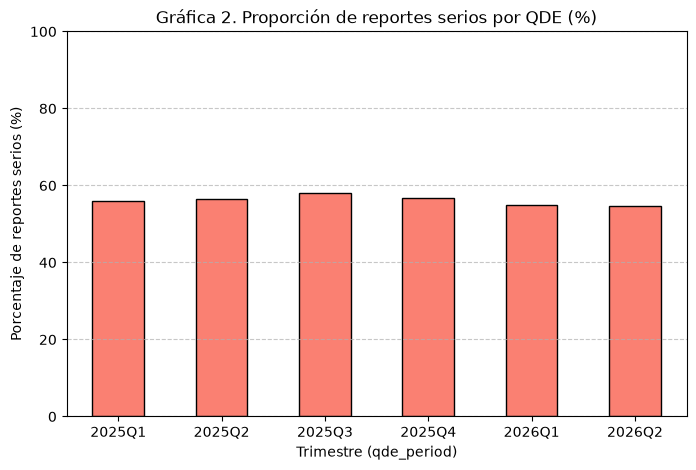

In [16]:

release_view = pd.read_parquet(
    "derived/metadata/release_view_metadata.parquet"
)

# Calcular la proporción de reportes serios por trimestre (qde_period)
# serious_any es booleano (True/False), por lo que .mean() calcula directamente la proporción
proporcion_serios = (
    release_view.groupby("qde_period")["serious_any"].mean() * 100
)
proporcion_serios.plot(
    kind="bar", color="salmon", edgecolor="black", figsize=(8, 5)
)
plt.title("Gráfica 2. Proporción de reportes serios por QDE (%)")
plt.xlabel("Trimestre (qde_period)")
plt.ylabel("Porcentaje de reportes serios (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.ylim(0, 100)

plt.show()

Responde: *¿La proporción de reportes serios parece estable a lo largo del periodo?*  
Se mantiene relativamente estable a lo largo de los 6 trimestres analizados, se encuentran entre  55% y 60% en release_view lo que indica un comportamiento homogeneo. 

## Gráfica 3. Información geográfica faltante

Para cada qde_period, calcula:

 $$\text{Missing}_q = 100 \cdot \frac{\#(\text{occurcountry faltante})}{N_q}$$

Construye una gráfica de barras del porcentaje de valores faltantes de occurcountry.

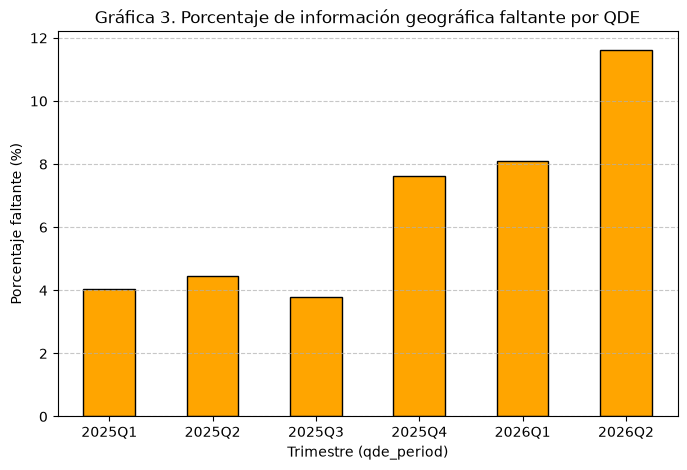

In [18]:

release_view = pd.read_parquet( "derived/metadata/release_view_metadata.parquet")

# Calcular el porcentaje de valores faltantes de occurcountry por trimestre
faltantes_geo = ( release_view.groupby("qde_period")["occurcountry"] .apply(lambda x: x.isna().mean() * 100))

faltantes_geo.plot( kind="bar", color="orange", edgecolor="black", figsize=(8, 5))

plt.title("Gráfica 3. Porcentaje de información geográfica faltante por QDE")
plt.xlabel("Trimestre (qde_period)")
plt.ylabel("Porcentaje faltante (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

Responde:

* ¿En qué QDE se observa el mayor porcentaje de información geográfica faltante?
  Se observa en los primero 3 trimestrs de estudio, donde los datos presentaban una mayor proporción de ausencia
* ¿Parece existir algún cambio temporal en la calidad o disponibilidad de esta variable?
  Sí, porque la variable de disponibilidad puede variar ligeramente entre liberaciones trimestrales debido a actualizaciones en los procesos de captura de las fuentes primarias y la menra en la que se publican las versiones.  
* ¿Por qué este resultado debe considerarse antes de comparar señales entre países?
  Porque si un trimestre o un país en específico acumula una tasa alta de faltantes, realizar análisis de desproporción geográfica o comparaciones directas sin tomarlo en ceunta podría sesgos importantes y subestimar las señales en determinadas regiones

## Gráfica 4. Número de QDE en los que aparece cada caso

Utiliza: case_history.parquet.

Construye una gráfica de barras para la variable:n_qde_periods.

El eje horizontal deberá representar: 1, 2, 3, 4, 5, 6
QDE y el eje vertical el número de safetyreportid.

Debido a la gran diferencia entre las frecuencias, puedes construir adicionalmente una versión utilizando escala logarítmica en el eje vertical.

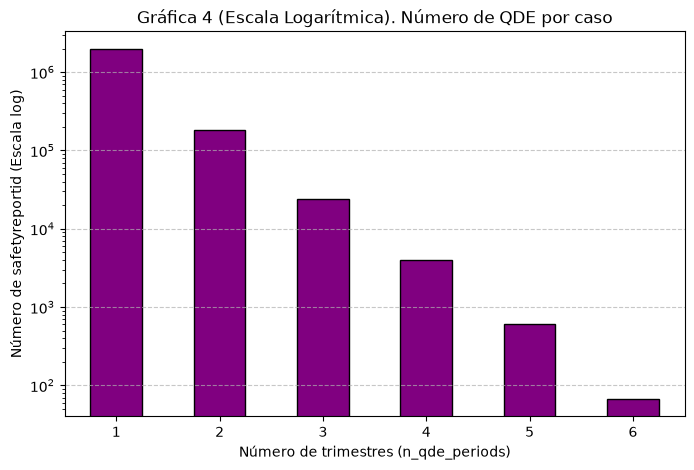

In [21]:
DERIVED_DIR = Path("derived/metadata")
case_history = pd.read_parquet(DERIVED_DIR / "case_history.parquet")
conteo_qde = case_history["n_qde_periods"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
conteo_qde.plot(kind="bar", color="purple", edgecolor="black")
plt.yscale("log")
plt.title("Gráfica 4 (Escala Logarítmica). Número de QDE por caso")
plt.xlabel("Número de trimestres (n_qde_periods)", fontsize=10)
plt.ylabel("Número de safetyreportid (Escala log)", fontsize=10)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Responde:

¿Qué nos dice esta distribución acerca de la frecuencia con la que los casos reaparecen en liberaciones posteriores?  
Nos dice que la mayoría de los casos, más de 90 % aparecen una vez en toda la ventana de estudio, lo que desmuestra que los reportes nuevos dominan la base y que la reaparición en multiples reportes es un fenómeno monoritario pero constante.

## Gráfica 5. Tipos de actualización de los casos

Utiliza:repeated_case_transitions_enriched.parquet.

Construye una gráfica de barras con la frecuencia de:

* updated_version_same_content;
* updated_version_reaction_change;
* updated_version_drug_change;
* updated_version_drug_and_reaction_change;
* same_version_exact_content;
* same_version_reaction_change_meddra_shift.
Ordena las barras de mayor a menor frecuencia.

Después construye una segunda versión utilizando porcentajes.

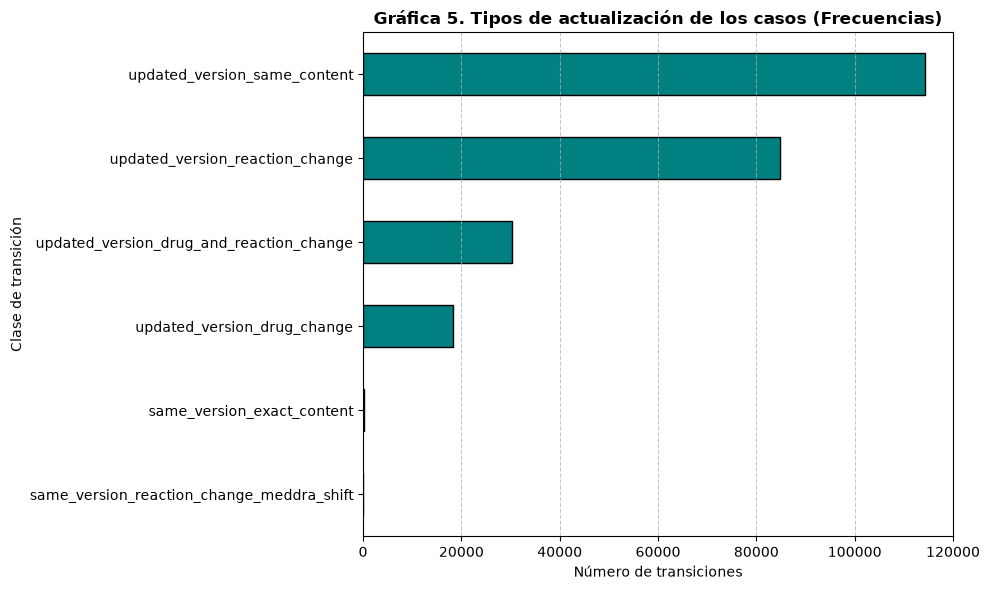

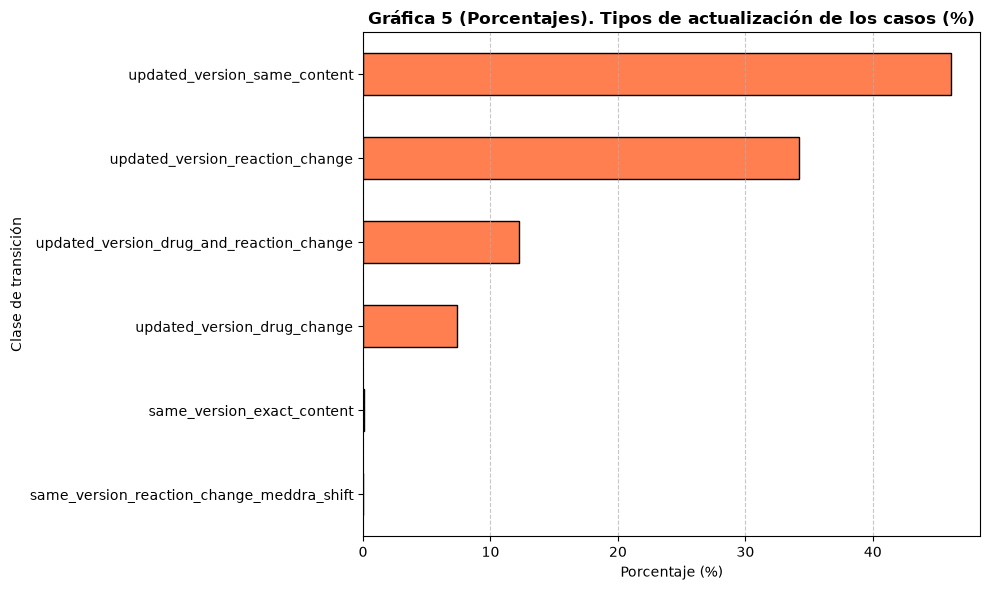

In [24]:
DERIVED_DIR = Path("derived/metadata")
df_transitions = pd.read_parquet(
    DERIVED_DIR / "repeated_case_transitions_enriched.parquet")
#obtener las frecuencias de la variable transition_class_check ordenadas de mayor a menor
conteo_clases = (df_transitions["transition_class_check"].value_counts().sort_values(ascending=True))

# gráfica de barras con frecuencias absolutas
plt.figure(figsize=(10, 6))
conteo_clases.plot(kind="barh", color="teal", edgecolor="black")
plt.title("Gráfica 5. Tipos de actualización de los casos (Frecuencias)",fontsize=12,fontweight="bold",)
plt.xlabel("Número de transiciones",)
plt.ylabel("Clase de transición", )
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# versión utilizando porcentajes
porcentajes_clases = (df_transitions["transition_class_check"].value_counts(normalize=True)
    .sort_values(ascending=True) * 100)

plt.figure(figsize=(10, 6))
porcentajes_clases.plot(kind="barh", color="coral", edgecolor="black")
plt.title("Gráfica 5 (Porcentajes). Tipos de actualización de los casos (%)",
    fontweight="bold",)
plt.xlabel("Porcentaje (%)")
plt.ylabel("Clase de transición",)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Responde:

1. ¿Cuál es el tipo de transición dominante?  
   Es *updated_version_same_conte* 
3. ¿Qué porcentaje de las transiciones con una nueva versión conserva el mismo contenido medicamento--reacción?  
 Conserva el mismo contenido un 46.11% de las transiciones 
5. ¿Por qué estos resultados muestran que nueva versión y nuevo contenido farmacológico no son conceptos equivalentes?  
   Porque desmuestra que al emitirse una version posterior de un reporte $\Delta v > 0$ es mas de la mitad de los casos se modifican los farmacos o las reacciones, pero en casi la mitad restante la nueva version obedece a actualizaciones admnistrativas, de metadatos o campos externos sin alterar los medicamentos ni las reacciones principales

## Gráfica 6. Cambios de reacción y versión MedDRA

Utiliza nuevamente:repeated_case_transitions_enriched.parquet.
Separa las transiciones en:$$meddra\_shift=False$$ y $$meddra\_shift=True$$


Para cada grupo calcula el porcentaje de transiciones donde:

reaction_changed = True.

Construye una gráfica con dos barras.

Compara tus resultados con los valores aproximados encontrados en el notebook: **40.42%**
sin cambio de versión MedDRA y **48.61%** cuando existe cambio de versión MedDRA.

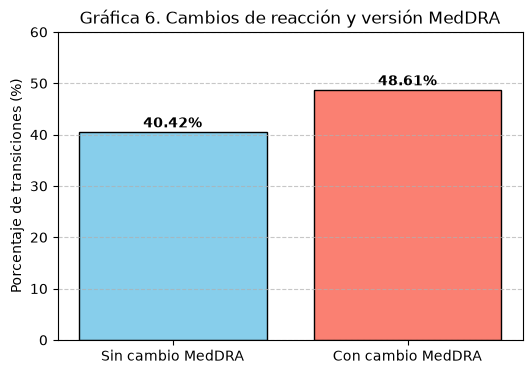

In [27]:
DERIVED_DIR = Path("derived/metadata")
ruta_transitions_enriched = ( DERIVED_DIR / "repeated_case_transitions_enriched.parquet")
df_transitions_enriched = pd.read_parquet(ruta_transitions_enriched)

Calcular los porcentajes requeridos usando el archivo
tabla_reaction_meddra = (df_transitions_enriched.groupby("meddra_shift")
.agg( n_transitions=("safetyreportid", "size"), n_reaction_changed=("reaction_changed", "sum"), )
 .reset_index())

tabla_reaction_meddra["pct_reaction_changed"] = ( 100 * tabla_reaction_meddra["n_reaction_changed"] / tabla_reaction_meddra["n_transitions"])

#extraer los valores para la gráfica
porcentajes = tabla_reaction_meddra["pct_reaction_changed"].tolist()
categorias = ["Sin cambio MedDRA", "Con cambio MedDRA"]

# 3. Construir la gráfica de barras sencilla
plt.figure(figsize=(6, 4))
plt.bar(categorias, porcentajes, color=["skyblue", "salmon"], edgecolor="black")

plt.title("Gráfica 6. Cambios de reacción y versión MedDRA")
plt.ylabel("Porcentaje de transiciones (%)")
plt.ylim(0, 60)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Mostrar los valores encima de cada barra
for i, v in enumerate(porcentajes):
  plt.text(i, v + 1, f"{v:.2f}%", ha="center", fontweight="bold")

plt.show()

Responde:

¿Es correcto concluir solamente con esta gráfica que el cambio de versión MedDRA causa los cambios observados en las reacciones? Explica por qué.  
No es correcto concluir causalidad de manera directa basandose unicamente en esta gráfica, aunque se observa una asociación clara y un incremento en el porcentaje de modificaciones de los términos preferidos cuando hay un cambio de versión en MedDRA (del 40.42% al 48.61%), las fronteras de versión del diccionario también coinciden con el paso del tiempo, el avance de los trimestres y nuevas liberaciones de datos, por lo tanto, el cambio refleja una asociación estadística, pero no demuestra por sí solo una relación de causalidad exclusiva.

## Parte D. Análisis propio

### Opción 3. Actualizaciones sin cambio medicamento--reacción

Selecciona únicamente:updated_version_same_content.

Investiga qué porcentaje de estas transiciones modifica:
* serious_any;
* occurcountry.
  
Explica por qué este resultado es importante antes de decidir que una versión nueva es redundante.

Total de transiciones analizadas: 114,292

--- Cambios en Seriedad (%) ---
serious_change_type
same                     99.664893
serious_to_nonserious     0.204739
nonserious_to_serious     0.130368
Name: proportion, dtype: float64

--- Cambios en País de Ocurrencia (%) ---
occurcountry_change_type
same_country        90.078921
changed_country      5.068596
known_to_missing     2.892591
both_missing         1.815525
missing_to_known     0.144367
Name: proportion, dtype: float64


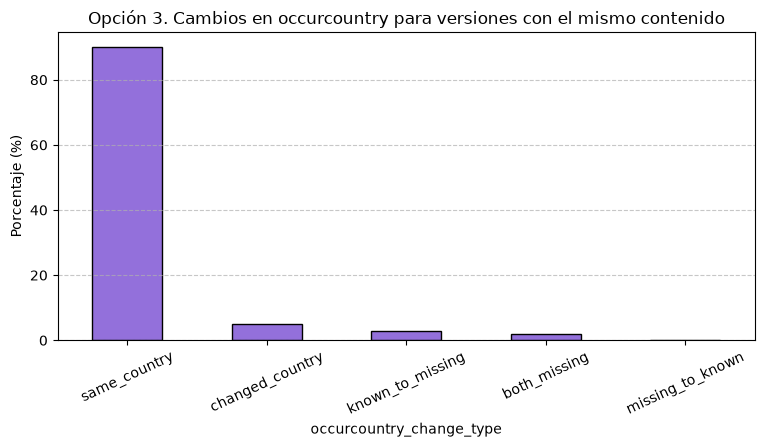

In [28]:
#Cargar la tabla enriquecida de transiciones
DERIVED_DIR = Path("derived/metadata")
df_transitions_enriched = pd.read_parquet(DERIVED_DIR / "repeated_case_transitions_enriched.parquet")

# Seleccionar únicamente las actualizaciones sin cambio en medicamento-reacción
df_updated_same_content = df_transitions_enriched[df_transitions_enriched["transition_class_check"]
    == "updated_version_same_content"].copy()

print(f"Total de transiciones analizadas: {len(df_updated_same_content):,}")

# calcular porcentajes de cambio en seriedad y geografía (occurcountry)
cambios_seriedad = ( df_updated_same_content["serious_change_type"].value_counts(normalize=True) * 100)
cambios_pais = ( df_updated_same_content["occurcountry_change_type"].value_counts(normalize=True)* 100
)

print("\n--- Cambios en Seriedad (%) ---")
print(cambios_seriedad)

print("\n--- Cambios en País de Ocurrencia (%) ---")
print(cambios_pais)

#  gráfica rápida de los cambios geográficos en este subgrupo
plt.figure(figsize=(9, 4))
cambios_pais.plot(kind="bar", color="mediumpurple", edgecolor="black")
plt.title(
    "Opción 3. Cambios en occurcountry para versiones con el mismo contenido"
)
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=25)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Se seleccionó de las transiciones  a updated_version_same_content el caul agrupa todas aquellas apariciones donde una nueva version del reporte conserva exactamnete el mismo contenido farmacologico pero presenta una actualizacion en su numeración de versión. Se evaluó qué procentaje modifica variables claves como el estatus de seriedad o el país de ocurrencia  

La gráfica y los numeros demuestran que aunque un reporte conserve exactamente el mismo contenido farmacologico (mismos medicamentos y mismas reacciones), no es una versión completamente redundante. Cerca del 10% de estos registros experimenta modificaciones en variables círticas como el país de ocurrencia o la seriedad, lo que justifica por que es indispensable gestionar adecuadamente las versiones dentro de los análisis de farmacovigilancia en lugar de descartarlas de manera simple. 

## Conclusión

Aprendí que la reaparición de un mismo identificador *safetyreportid* entre extractos trimestrales no debe interpretarse automáticamente como un duplicado simple. Cerca del 10% de los casos experimentan un seguimiento a lo largo del tiempo, y las nuevas versiones reflejan actualizaciones dinámicas que van desde modificaciones clínicas hasta ajustes de diccionarios, como las actualizaciones del sistema MeDRA en los términos de reacción. Asimismo, se comprobó que incluso en aquellos reportes que conservan exactamente el mismo perfil farmacologico, se presentan variaciones criticas en variables analíticas clave como el estatus de seriedad o el país de ocurrencia.

Es fundamental resolver este problema de gestión de versiones antes de calcular señales de farmacovigilancia porque una deduplicación o la suposición de que los registros nuevos son redundantes introduciría sesgos graves. Dependiendo de si se evalúa una perspectiva temporal mediante liberaciones trimestrales *release_view*  o una cohorte transversal de casos únicos *case_latest_view*, las decisiones de limpieza impactan de manera directa la precisión de los analisis temporales, geograficos y de desproporcionalidad. Por lo tanto, comprender la naturaleza de cada observación garantiza la integridad de los resultados epidemiológicos obtenidos.

Anexo mi notebook  donde estuve trabajando. 

file:///C:/Users/deade/Downloads/sesion%20dos%20faers.html